In [ ]:
# Load data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_ind      # ttest_ind - is used for comparing independent groups

In [ ]:
df = pd.read_csv("ecommerce_clean_data.csv")

In [ ]:
# filter delivered orders

test_df = df[df['OrderStatus'] == "Delivered"].copy()

In [ ]:
test_df.head()

,OrderID,OrderDate,CustomerID,PaymentMethod,OrderStatus,CustomerName,Gender,Age,City,Region,...,Profit,ProductName,Category,CostPrice,SellingPrice,Year,Month,MonthName,YearMonth,ProfitMarginPct
0,O00001,2026-01-19,C0484,UPI,Delivered,Customer_0484,Female,31,Pune,West,...,12649.20,Mouse,Electronics,5353.0,10018.0,2026,1,January,2026-01,37.136683
1,O00001,2026-01-19,C0484,UPI,Delivered,Customer_0484,Female,31,Pune,West,...,6532.80,Shampoo,Beauty,3112.0,5568.0,2026,1,January,2026-01,41.167574
2,O00002,2026-02-14,C0450,Credit Card,Delivered,Customer_0450,Female,23,Hyderabad,South,...,3909.45,Table Lamp,Home,5905.0,10331.0,2026,2,February,2026-02,39.833613
3,O00002,2026-02-14,C0450,Credit Card,Delivered,Customer_0450,Female,23,Hyderabad,South,...,2006.80,Air Fryer,Home,3425.0,4363.0,2026,2,February,2026-02,12.776632
4,O00003,2025-11-21,C0523,Credit Card,Delivered,Customer_0523,Female,60,Delhi,North,...,4543.90,T-Shirt,Fashion,3999.0,6601.0,2025,11,November,2025-11,36.229758


In [ ]:
# Understand discount data

test_df['DiscountPct'].describe()

count    10970.000000
mean        10.737922
std          7.095532
min          0.000000
25%          5.000000
50%         10.000000
75%         15.000000
max         25.000000
Name: DiscountPct, dtype: float64

In [ ]:
# Create two groups

In [ ]:
## step - 1 : Order-Level aggregation

order_level = (test_df.
    groupby("OrderID")
    .agg(OrderValue = ("SalesAmount","sum"),
         DiscountPct = ("DiscountPct","mean"))
    .reset_index()
)

In [ ]:
# Define Groups

order_level

,OrderID,OrderValue,DiscountPct
0,O00001,49930.00,10.000000
1,O00002,25521.25,7.500000
2,O00003,12541.90,5.000000
3,O00004,41731.20,15.000000
4,O00005,57555.85,15.000000
...,...,...,...
4381,O04995,19430.90,10.000000
4382,O04996,12673.50,7.500000
4383,O04998,24658.60,5.000000
4384,O04999,24078.25,10.000000


In [ ]:
discount_group = order_level[order_level["DiscountPct"]>0]["OrderValue"]
discount_group

0       49930.00
1       25521.25
2       12541.90
3       41731.20
4       57555.85
          ...   
4381    19430.90
4382    12673.50
4383    24658.60
4384    24078.25
4385    21834.00
Name: OrderValue, Length: 4230, dtype: float64

In [ ]:
no_discount_group = order_level[order_level["DiscountPct"] == 0]["OrderValue"]
no_discount_group

28      33435.0
58      31488.0
161     16574.0
181      4367.0
203      7607.0
         ...   
4200    13202.0
4222    21582.0
4290    12456.0
4303    36372.0
4312     3517.0
Name: OrderValue, Length: 156, dtype: float64

In [ ]:
# Group sizes

print("Discount Orders : ",len(discount_group))
print("No Discount Orders : ",len(no_discount_group))

Discount Orders :  4230
No Discount Orders :  156


In [ ]:
# Group Mean

print("Discount AOV : ",discount_group.mean())
print("No Discount AOV : ",no_discount_group.mean())

Discount AOV :  35550.653794326245
No Discount AOV :  18799.19230769231


In [ ]:
# Group Median

print("Discount Median : ",discount_group.median())
print("No Discount Median : ",no_discount_group.median())

Discount Median :  32649.199999999997
No Discount Median :  14292.0


In [ ]:
# Visual Comparison

comparison_df = pd.DataFrame({
    "AOV" : pd.concat(
            [discount_group, no_discount_group],
            ignore_index = True
    ),
    "Group" : (
        ["Discount"] * len(discount_group)
        +
        ["No Discount"] * len(no_discount_group)
    )
})

In [ ]:
comparison_df

,AOV,Group
0,49930.00,Discount
1,25521.25,Discount
2,12541.90,Discount
3,41731.20,Discount
4,57555.85,Discount
...,...,...
4381,13202.00,No Discount
4382,21582.00,No Discount
4383,12456.00,No Discount
4384,36372.00,No Discount


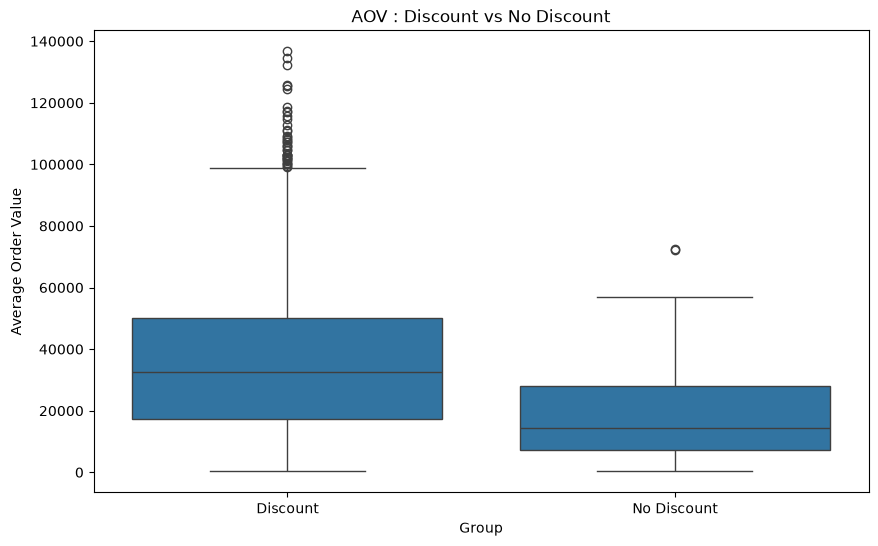

In [ ]:
plt.figure(figsize=(10,6))

sns.boxplot(                                # boxplot - used for outliers identifaction and for comparing groups also
    data = comparison_df,
    x = "Group",
    y = "AOV"
)

plt.title("AOV : Discount vs No Discount")
plt.xlabel("Group")
plt.ylabel("Average Order Value")

plt.show()

In [ ]:
# Independent T-Test

t_test, p_value = ttest_ind(
    discount_group,
    no_discount_group,
    equal_var = False
)

In [ ]:
# Result

print("T-Statistic : ",t_test)
print("P-Value : ",p_value)

T-Statistic :  13.875792073637808
P-Value :  1.8665022824881592e-30


In [ ]:
# Decision Rule

alpha = 0.05

if p_value < alpha:
    print("Reject H0")
else:
    print("Failed to reject H0")

Reject H0


In [ ]:
from scipy.stats import ttest_ind

result = ttest_ind(
    discount_group,
    no_discount_group,
    equal_var = False
)

print(result)

TtestResult(statistic=np.float64(13.875792073637808), pvalue=np.float64(1.8665022824881592e-30), df=np.float64(184.67236156483705))


In [ ]:
result.confidence_interval()

ConfidenceInterval(low=np.float64(14369.699004998576), high=np.float64(19133.223968269296))

In [ ]:
# effect difference

AOV_difference = (
    discount_group.mean()
    -
    no_discount_group.mean()
)

AOV_difference

np.float64(16751.461486633936)

In [ ]:
# Final Hypothesis Testing Summary

hypothesis_result = pd.DataFrame({
    "Metric" : [
        "Disocunt AOV",
        "No Discount AOV",
        "Difference",
        "T-Statistic",
        "P-Value",
        "Alpha"
    ],
    "Value" : [
        discount_group.mean(),
        no_discount_group.mean(),
        AOV_difference,
        t_test,
        p_value,
        alpha
    ]
})

print(hypothesis_result)

            Metric         Value
0     Disocunt AOV  3.555065e+04
1  No Discount AOV  1.879919e+04
2       Difference  1.675146e+04
3      T-Statistic  1.387579e+01
4          P-Value  1.866502e-30
5            Alpha  5.000000e-02


MACHINE LEARNING PART

BUSINESS QUES : "ARE WE PREDICT THE EXPECTED PROFIT FROM ORDERS"

In [ ]:
# STEP  1 - IMPORT LIBRARIES

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [ ]:
# STEP 2 -  Load Dataset

df = pd.read_csv("ecommerce_clean_data.csv")

In [ ]:
df.head()

,OrderID,OrderDate,CustomerID,PaymentMethod,OrderStatus,CustomerName,Gender,Age,City,Region,...,Profit,ProductName,Category,CostPrice,SellingPrice,Year,Month,MonthName,YearMonth,ProfitMarginPct
0,O00001,2026-01-19,C0484,UPI,Delivered,Customer_0484,Female,31,Pune,West,...,12649.20,Mouse,Electronics,5353.0,10018.0,2026,1,January,2026-01,37.136683
1,O00001,2026-01-19,C0484,UPI,Delivered,Customer_0484,Female,31,Pune,West,...,6532.80,Shampoo,Beauty,3112.0,5568.0,2026,1,January,2026-01,41.167574
2,O00002,2026-02-14,C0450,Credit Card,Delivered,Customer_0450,Female,23,Hyderabad,South,...,3909.45,Table Lamp,Home,5905.0,10331.0,2026,2,February,2026-02,39.833613
3,O00002,2026-02-14,C0450,Credit Card,Delivered,Customer_0450,Female,23,Hyderabad,South,...,2006.80,Air Fryer,Home,3425.0,4363.0,2026,2,February,2026-02,12.776632
4,O00003,2025-11-21,C0523,Credit Card,Delivered,Customer_0523,Female,60,Delhi,North,...,4543.90,T-Shirt,Fashion,3999.0,6601.0,2025,11,November,2025-11,36.229758


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12558 entries, 0 to 12557
Data columns (total 27 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          12558 non-null  str    
 1   OrderDate        12558 non-null  str    
 2   CustomerID       12558 non-null  str    
 3   PaymentMethod    12558 non-null  str    
 4   OrderStatus      12558 non-null  str    
 5   CustomerName     12558 non-null  str    
 6   Gender           12558 non-null  str    
 7   Age              12558 non-null  int64  
 8   City             12558 non-null  str    
 9   Region           12558 non-null  str    
 10  SignupDate       12558 non-null  str    
 11  OrderDetailID    12558 non-null  str    
 12  ProductID        12558 non-null  str    
 13  Quantity         12558 non-null  int64  
 14  UnitPrice        12558 non-null  float64
 15  DiscountPct      12558 non-null  float64
 16  SalesAmount      12558 non-null  float64
 17  Profit           12558 

In [ ]:
df['OrderDate'] = pd.to_datetime(df["OrderDate"])

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12558 entries, 0 to 12557
Data columns (total 27 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   OrderID          12558 non-null  str           
 1   OrderDate        12558 non-null  datetime64[us]
 2   CustomerID       12558 non-null  str           
 3   PaymentMethod    12558 non-null  str           
 4   OrderStatus      12558 non-null  str           
 5   CustomerName     12558 non-null  str           
 6   Gender           12558 non-null  str           
 7   Age              12558 non-null  int64         
 8   City             12558 non-null  str           
 9   Region           12558 non-null  str           
 10  SignupDate       12558 non-null  str           
 11  OrderDetailID    12558 non-null  str           
 12  ProductID        12558 non-null  str           
 13  Quantity         12558 non-null  int64         
 14  UnitPrice        12558 non-null  float64       
 

In [ ]:
# STEP 3 - Define Target

target = "Profit"

In [ ]:
# STEP 4 - understanding data leakage

In [ ]:
# STEP 5 - Features selection

features = [
    "Quantity",
    "UnitPrice",
    "DiscountPct",
    "Category",
    "Region",
    "PaymentMethod"
]

In [ ]:
# STEP 6 - X and y

X = df[features]
y = df[target]

In [ ]:
# Check missing values

X.isnull().sum()

Quantity         0
UnitPrice        0
DiscountPct      0
Category         0
Region           0
PaymentMethod    0
dtype: int64

In [ ]:
y.isnull().sum()

np.int64(0)

In [ ]:
# STEP 8 -  Identify data types

X.dtypes

Quantity           int64
UnitPrice        float64
DiscountPct      float64
Category             str
Region               str
PaymentMethod        str
dtype: object

In [ ]:
# STEP 9 - Train-Test-Split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42)

In [ ]:
# STEP 10 -  Categorical columns

categorical_features = [
    "Category",
    "Region",
    "PaymentMethod"
]

numeric_features = [
    "Quantity",
    "UnitPrice",
    "DiscountPct"
]

In [ ]:
# STEP 11 -  One-Hot Encoding

preprocessor = ColumnTransformer(
    transformers = [
        (
            "cat",
            OneHotEncoder(handle_unknown = "ignore"),
            categorical_features
        )
        
    ],
    remainder = "passthrough"
)

In [ ]:
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. 

In [ ]:
# STEP 12 - MODEL

model = RandomForestRegressor(
    n_estimators = 100,
    n_jobs = -1,
    random_state = 42
)

In [ ]:
# STEP 13 - Pipeline

pipeline = Pipeline(
    steps = [
        ("Preprocessor", preprocessor),
        ("Model", model)
    ]
)

In [ ]:
# STEP 14 - Train Model

pipeline.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Preprocessor', ...), ('Model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Quantity','UnitPrice','DiscountPct','Category','Region','PaymentMethod']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenat

In [ ]:
# STEP 15 - Predicitions

y_pred = pipeline.predict(X_test)

In [ ]:
# STEP 16 - Actual vs Predicted

comparison = pd.DataFrame({
    "Actual Profit" : y_test.values,
    "Predicted Profit" : y_pred
})

comparison.head(10)

,Actual Profit,Predicted Profit
0,3068.40,3052.0590
1,8642.00,9187.6380
2,502.35,501.1745
3,2876.35,2879.2095
4,1755.80,1752.9820
5,630.00,621.4920
6,-233.25,-156.0295
7,2379.80,2366.0420
8,2291.30,2309.6000
9,2184.00,2197.0000


In [ ]:
# STEP 17 - MAE

mae = mean_absolute_error(y_test,y_pred)
print("Mean Absolute Error : ",mae)

Mean Absolute Error :  74.62238634554251


In [ ]:
# STEP 18 - RMSE

rmse = np.sqrt(mean_squared_error(y_test,y_pred))
print("Root Mean Squared Error : ",rmse)

Root Mean Squared Error :  211.25107571650383


In [ ]:
# STEP 19 -  R2 Score

r2_score = r2_score(y_test,y_pred)
print("R2 Score : ", r2_score)

R2 Score :  0.9979892693153789


In [ ]:
# STEP 20 - Complete Model Evaluation

print("MAE : ", mae)
print("RMSE : ", rmse)
print("R2 : ", r2_score)

MAE :  74.62238634554251
RMSE :  211.25107571650383
R2 :  0.9979892693153789


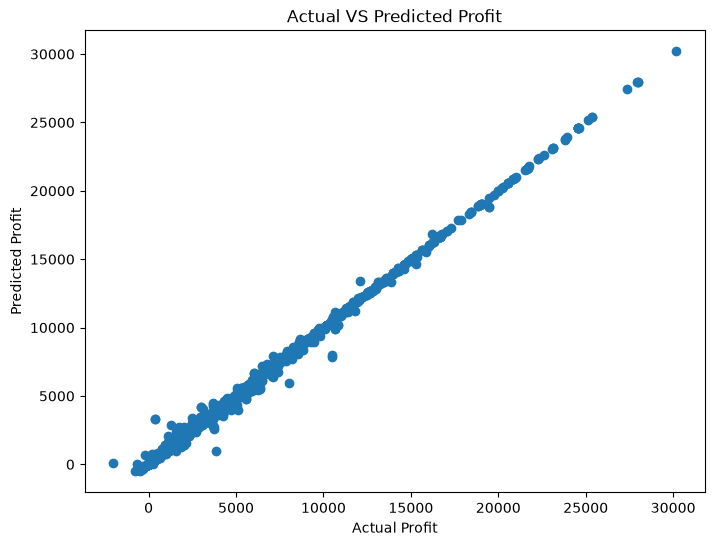

In [ ]:
# STEP 21 - Actual vs Predicted visualization

import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(y_test,y_pred)

plt.title("Actual VS Predicted Profit")
plt.xlabel("Actual Profit")
plt.ylabel("Predicted Profit")

plt.show()

In [ ]:
# STEP 22 - Residual (difference between actual & predicted)

residuals = y_test - y_pred

residuals.describe()

count    2512.000000
mean        0.536251
std       211.292456
min     -2976.040000
25%       -15.104250
50%         0.000000
75%        13.936000
max      2856.813500
Name: Profit, dtype: float64

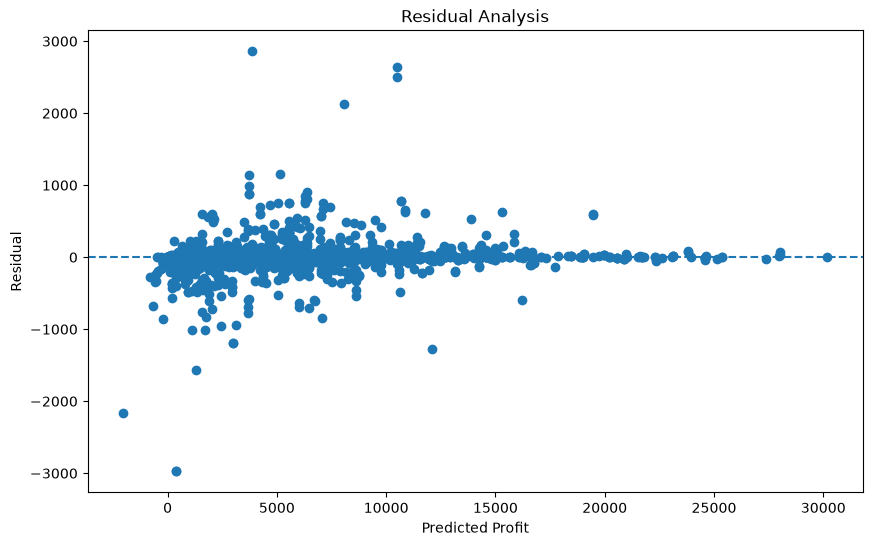

In [ ]:
# Visualize the residuals

plt.figure(figsize=(10,6))

plt.scatter(y_test,residuals)

plt.axhline(0, linestyle = "--")

plt.title("Residual Analysis")
plt.xlabel("Predicted Profit")
plt.ylabel("Residual")

plt.show()